In [1]:
from IPython.core.display import HTML
table_css = 'table {align:left;display:block}'
HTML('<style>{}</style>'.format(table_css))

# EFR sensitivity

Main script to postprocess ISIMIP output and calculate water scarcity indices



**TO DO**
- check ptotww values calculation for MATSIRO and LPJmL

**Notes**
- industrial = elec+manu (some models have it seperately)
- Not all GHMs use DDM30: to check for each! (CLM not, JULES not)
- Implications with how actual water use is defined/modeled in H08 (no constraints?) see mail Naota
- How to represent local water availability? dis - dis_upstream grid cell => how much water is produced locally, but in the dis term the water use is already distracted. 
- qrunoff is result of only local processes and then goes through lateral flow (reservoirs and lakes) for some models like WaterGAP, use for local water availability discharge from the direct upstream gridcells, plus the local runoff (discharge of the cell itself is already subtracted with the water demand)
- H08 (and maybe others): actual water use == pot water use (no limitations in ISIMIP simulations): double check mail Naota

**Model availability** 


|      -            | rcp26soc          | rcp26soc        | rcp60soc           | rcp60soc        |
|------------------|:--------         :|:------:         | :------:           |:------:         |
|                  |          dis/qtot |          use/ww |          dis/qtot  |          use/ww |
| **CWatM**        | x                 | x               |  x                 | x               |  
| **H08**          | x                 | x               |  x                 | x               |  
| **LPJmL**        | x                 | o               |  x                 | o               |  
| **MATSIRO**      | x                 | o               |  x                 | o               |  
| **WaterGAP2-2e** | o                 | o               |  o                 | o               | 


/rhea/scratch/brussel/vo/000/bvo00012/vsc10055/waterscarcity/2025_Vanderkelen_etal/preprocessing_isimip/init.py:186: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  d_time_ncfile = {'historical': pd.date_range(start='1861-01-01', end='2006-01-01', freq='M'),
/rhea/scratch/brussel/vo/000/bvo00012/vsc10055/waterscarcity/2025_Vanderkelen_etal/preprocessing_isimip/init.py:187: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  'rcp26': pd.date_range(start='2006-01-01', end='2100-01-01', freq='M'),
/rhea/scratch/brussel/vo/000/bvo00012/vsc10055/waterscarcity/2025_Vanderkelen_etal/preprocessing_isimip/init.py:188: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  'rcp60':pd.date_range(start='2006-01-01', end='2100-01-01', freq='M') }
/rhea/scratch/brussel/vo/000/bvo00012/vsc10055/waterscarcity/2025_Vanderkelen_etal/preprocessing_isimip/init

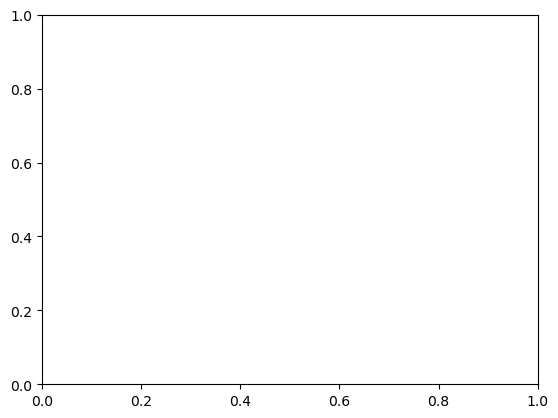

In [1]:
# import modules
import os
import xarray as xr
import matplotlib.pyplot as plt
# define isimip phase  - different initialisation needed

# define phase manually in init script
from init import *

from functions import *
#from calc_upstream import *
import pandas as pd
import cartopy.crs as ccrs
# to show plots in the notebook
%matplotlib inline 
set_plot_param()
    

# flags
testing = False
calc_wsindex = False
load_wsindex = False
calc_exposure = True
calc_duration = False
calc_falkenmark= False
save_intermediate = True
preprocess_pop = True
calc_waterdeficit = False
calc_waterdeficit_duration = False
calc_waterdeficit_intensity = False

calc_withdrawal_persector = True
calc_deficit_persector = True
aggregation_flag = 'sum' # sum:  number of exposerd months per year
                         # binary: calculate annual maximum (at least one month with water scarcity => water scarce year)
                        # integer: number of months per year that need to be water scarce in order to have a waterscarce year. 
save_annual = False
# water scarcity threshold
ws_threshold = 0.4
falkenmark_threshold = 1000 # m³/cap

map_proj = ccrs.Robinson(central_longitude=0, globe=None)



In [2]:
# define ISIMIP models, forcings and variables
models    = ['H08', 'CWatM', 'LPJmL', 'MATSIRO']

forcings  = ['gfdl-esm2m', 'ipsl-cm5a-lr', 'hadgem2-es', 'miroc5']

# do initialisation of global variables
# define directory where to put processed netcdf files

if testing: 

    # for testing, only load one model and forcing
    models = [models[0]]
    forcings = [forcings[0]]
    scenarios = [scenarios[0]]
    
    model = models[0]
    scenario = scenarios[0]
    forcing = forcings[0]
                    

In [3]:
# Load routing data

#da_flowdir = xr.open_dataarray(routingdir +'ddm30_flowdir_cru_neva.nc')
da_basins  = xr.open_dataarray(routingdir +'ddm30_basins_cru_neva.nc')
#da_slopes  = xr.open_dataarray(routingdir +'ddm30_slopes_cru_neva.nc')

# load cell area
da_cellarea = xr.open_dataarray( scriptsdir+'/data/2b/upstream_calc/cellarea.nc')

# load land mask
landmask = da_basins>0


In [4]:
def get_efr(qtot, method = "VMF"):


    # Average Monthly Flow method from Pastor et al., 2014
    if method == "VMF":
        # compute yearly means
        qtot_ymean = qtot.groupby('time.year').mean()

        # intialise lowflow, mediumflow and highflow 
        mask_lowflow    = xr.DataArray(data = np.zeros_like(qtot.values),coords=qtot.coords, dims=qtot.dims)
        mask_mediumflow = xr.DataArray(data = np.zeros_like(qtot.values),coords=qtot.coords, dims=qtot.dims)
        mask_highflow   = xr.DataArray(data = np.zeros_like(qtot.values),coords=qtot.coords, dims=qtot.dims)


        # for every year, calculate masks with corresponding annual means
        
        for group_name, group_da in qtot.groupby('time.year'):
            mask_lowflow[mask_lowflow.time.dt.year == group_name] = group_da <= 0.4*qtot_ymean.where(qtot_ymean.year==group_name, drop=True).squeeze()
            mask_mediumflow[mask_mediumflow.time.dt.year == group_name] = group_da > 0.8*qtot_ymean.where(qtot_ymean.year==group_name, drop=True).squeeze()

        mask_highflow = (mask_lowflow + mask_mediumflow) == 0 # mediumflow is in between high flow and low flow


        # determine environmental flow conditions
        efr =   qtot

        # apply inverse masks, as where function assigns values to places where mask is not true
        efr = efr.where(mask_lowflow==0   ,  0.6 * qtot)
        efr = efr.where(mask_mediumflow==0,  0.3 * qtot)
        efr = efr.where(mask_highflow==0  ,  0.45 * qtot)


    elif method == "Tessmann": #Tessmann 1980

        # (1) compute yearly mean (dims: ['year', ...])
        qtot_yearly = qtot.groupby("time.year").mean("time")

        # (2) align yearly means to the original time axis
        qtot_annual_by_time = qtot_yearly.sel(year=qtot["time.year"])

        # (3) define the three conditions (lazy; no materialization)
        cond_low  = (qtot <= 0.4 * qtot_annual_by_time)   # low flow
        cond_high = (qtot >           qtot_annual_by_time)   # high flow
        # medium is the remaining case: not low and not high
        # but you can also express it as (qtot > 0.4 * qtot_annual_by_time) & (~cond_high)
        # we'll rely on nested where below to avoid creating it explicitly

        # (4) build efr in one expression (no intermediate full-size masks)
        # semantics you used: low -> qtot, high -> 0.4*qtot, medium -> 0.4*qtot_yearly_for_that_time
        efr = xr.where(
            cond_low,
            qtot,                                           # where low: keep qtot
            xr.where(
                cond_high,
                0.4 * qtot,                                 # where high: 0.4*qtot
                0.4 * qtot_annual_by_time                    # else (medium): use 0.4 * yearly mean (aligned to time)
            )
        )
            

        
    elif method == "AFQ": # Annual Flow Quantiles (non-parametric method based on Q50 and Q95)
        # doesn't work yet because of negative runoff values for some simulations!!!


        # compute yearly means
        qtot_ymean = qtot.groupby('time.year').mean()
        
        q_90 = qtot.where(qtot>0,0).quantile(0.9, dim='time')
        q_50 = qtot.where(qtot>0,0).quantile(0.5, dim='time')
        q_ymean = qtot.groupby('time.year').mean()

        mask_lowflow    = xr.DataArray(data = np.zeros_like(qtot.values),coords=qtot.coords, dims=qtot.dims)
        mask_highflow   = xr.DataArray(data = np.zeros_like(qtot.values),coords=qtot.coords, dims=qtot.dims)

        for group_name, group_da in qtot.groupby('time.year'):
            mask_lowflow[mask_lowflow.time.dt.year == group_name] = group_da <= qtot_ymean.where(qtot_ymean.year==group_name, drop=True).squeeze()
            mask_highflow[mask_highflow.time.dt.year == group_name] = group_da > qtot_ymean.where(qtot_ymean.year==group_name, drop=True).squeeze()


        # determine environmental flow conditions
        efr =   qtot

        # apply inverse masks, as where function assigns values to places where mask is not true
        efr = efr.where(mask_lowflow==0 ,q_90)
        efr = efr.where(mask_highflow==0, q_50)


    ## no ERF
    elif method == "noEFR":
        efr = qtot * 0.0

    return efr

## Manual verification

In [5]:
methods = ["VMF","Tessmann","noEFR"]
 
d_ef_fraction_allruns = {}
models = ['H08']

# loop over models
for model in models:
    # loop over GCM forcings
    for forcing in forcings: 
        print('processing '+model + ' ' + forcing)
        d_ef_fraction_allscenarios = {}


        for scenario in scenarios:
            print(scenario)

            #calc_water_deficit(model, forcing, scenario, da_cellarea, landmask, pop)
            
            qtot = load_simulation('qtot', datadir, model, forcing, scenario)

            d_ef_fraction = {}

            for method in methods: 
                efr = get_efr(qtot, method = method)
                ef_fraction = (efr/qtot).groupby('time.year').mean('time')
                d_ef_fraction[method] = ef_fraction

                d_ef_fraction_allscenarios[scenario] = d_ef_fraction
        
        
        key = f"{model}_{forcing}"
        d_ef_fraction_allruns[key] = d_ef_fraction_allscenarios



processing H08 gfdl-esm2m
historical
rcp26
rcp60
processing H08 ipsl-cm5a-lr
historical
rcp26
rcp60
processing H08 hadgem2-es
historical
rcp26
rcp60
processing H08 miroc5
historical
rcp26
rcp60


In [6]:
def dict_to_dataset_v2(d_ef_fraction_allruns):
    """
    Convert nested dictionary to xarray Dataset using concat.
    """
    
    # First, concatenate over methods
    method_datasets = []
    for model_forcing, scenarios_dict in d_ef_fraction_allruns.items():
        scenario_datasets = []
        for scenario, methods_dict in scenarios_dict.items():
            # Concatenate all methods for this scenario
            method_das = []
            for method, da in methods_dict.items():
                da_with_method = da.expand_dims(method=[method])
                method_das.append(da_with_method)
            scenario_combined = xr.concat(method_das, dim='method')
            
            # Add scenario dimension
            scenario_combined = scenario_combined.expand_dims(scenario=[scenario])
            scenario_datasets.append(scenario_combined)
        
        # Concatenate all scenarios for this model_forcing
        model_forcing_combined = xr.concat(scenario_datasets, dim='scenario')
        
        # Add model_forcing dimension
        model_forcing_combined = model_forcing_combined.expand_dims(model_forcing=[model_forcing])
        method_datasets.append(model_forcing_combined)
    
    # Concatenate all model_forcings
    ds = xr.concat(method_datasets, dim='model_forcing')
    
    return ds

# Convert to dataset
ds_ef_fraction = dict_to_dataset_v2(d_ef_fraction_allruns)


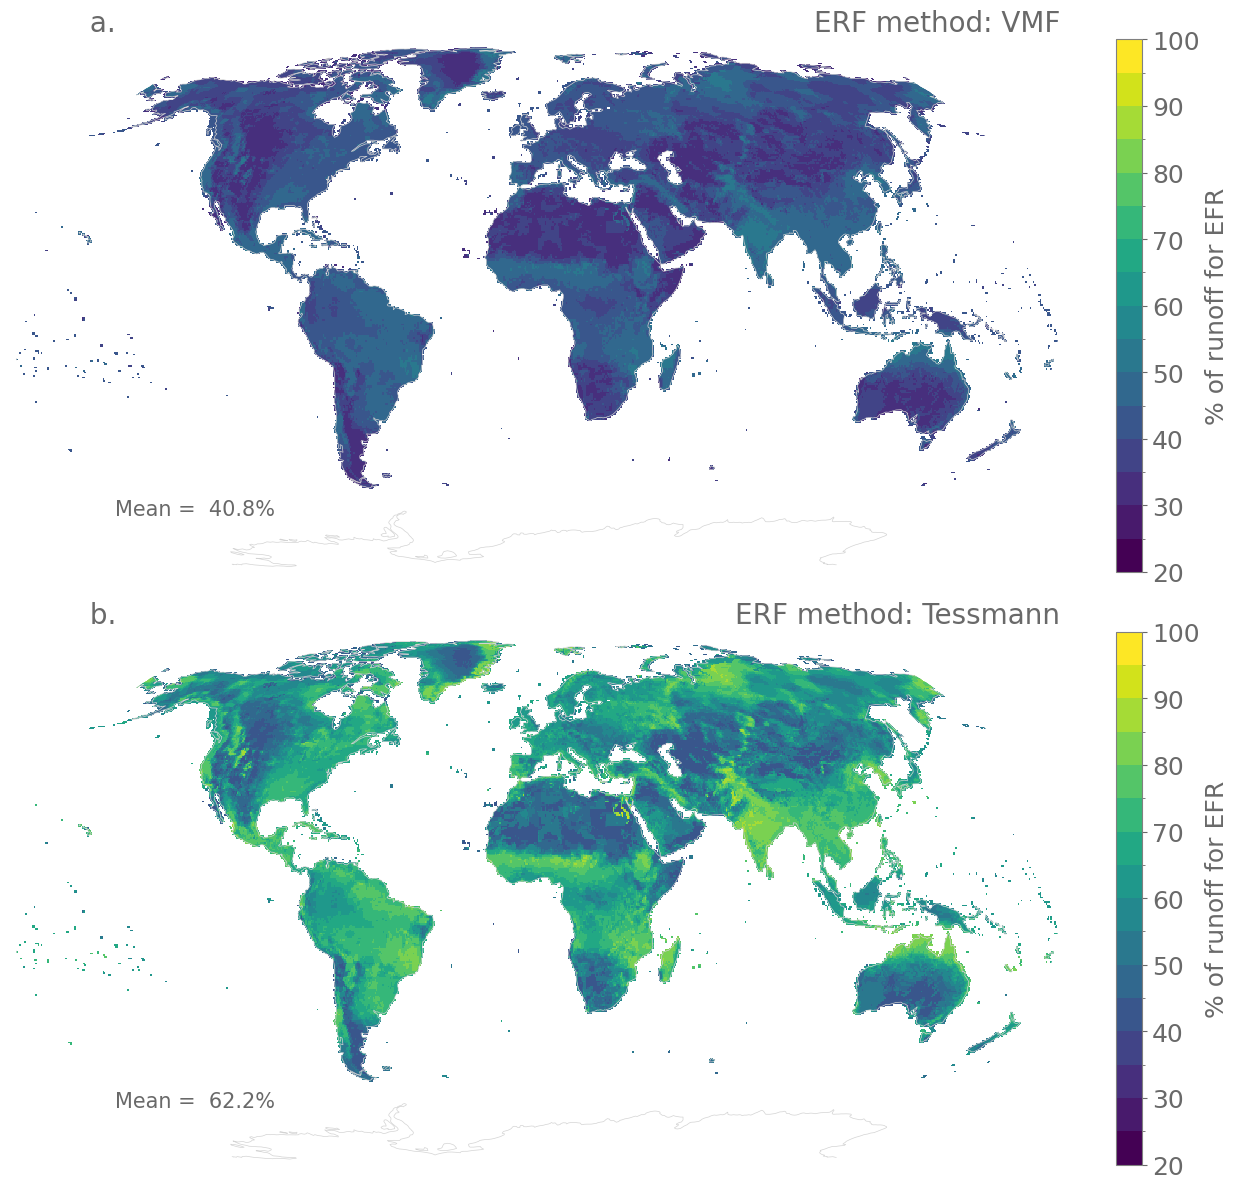

In [7]:
da_final_mean = ds_ef_fraction.mean(dim=('model_forcing'))

da_final_historical = da_final_mean.sel(scenario="historical").sel(year=slice(1960,1989)).mean('year')
da_final_fut = da_final_mean.sel(scenario=slice("rcp26","rcp60")).mean('scenario').sel(year=slice(2070,2099)).mean('year')

da_final_scenario_mean = da_final_mean.mean(dim=('scenario')).mean('year')
##HIST

fig, axes = plt.subplots(2,1,figsize=(15,12), subplot_kw={'projection':map_proj})
axes = axes.flatten()

mpl.rc('xtick',labelsize=18)
mpl.rc('ytick',labelsize=18)
mpl.rc('axes',labelsize=18)

labels = ["a","b","c"]
d_method_text = {"noEFR": "without Environmental Flow requirement", "Tessmann": "Tessmann (1980)", "VMF": "Variable Monthly Flow"}
methods_toplot = ["VMF","Tessmann"]
for i, method in enumerate(methods): 

    if method == "noEFR":
        continue
    else: 
        label=labels[i]
        ax = axes[i]
        ax.axis('off')
        ax.coastlines(color='lightgray',linewidth=0.5)
        levels = np.arange(20,105,5)
        #da_final_historical.isel(method=i).plot(ax=ax, cbar_kwargs={'label': '$\Delta$ water deficit (km$^{3}$ year$^{-1}$)', 'fraction': 0.02, 'pad': 0.04,'ticks': levels}, cmap='BrBG_r', levels=levels, transform=ccrs.PlateCarree())
        (da_final_scenario_mean*100).isel(method=i).plot(ax=ax, cbar_kwargs={'label': '% of runoff for EFR', 'fraction': 0.02, 'pad': 0.04}, transform=ccrs.PlateCarree(), levels=levels)

        text = 'Mean =  '+str(np.round((da_final_scenario_mean*100).isel(method=i).mean(),1).values)+'%'
        ax.text(0.1, 0.1, text, transform=ax.transAxes, va='bottom', ha='left', fontsize=15)

        ax.set_ylabel('')
        ax.set_xlabel('')
        ax.set_title('')

        ax.set_title('ERF method: '+method, loc="right", fontsize=20)
        ax.set_title(f'         {label}.', loc='left', fontsize=20);

fig.tight_layout()
plt.savefig('/scratch/brussel/vo/000/bvo00012/vsc10055/waterscarcity/2025_Vanderkelen_etal/lifetime_waterdeficit/figures/maps_efr.png', bbox_inches='tight',dpi=600)

      